# Chapter 92: Religion, Belonging, Human Capital, and Social Insurance

This notebook reruns four worked examples from the chapter: a public benefit that replaces congregational support, religious capital that makes switching costly, the time cost of fellowship, and a mutual-aid pool facing correlated losses. Every number is one of the chapter's hypothetical teaching values in utility or resource units, not an estimate of any real community; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def capital_stock_decay(K, delta, periods=1, investment=0.0):
    """Stock after `periods` of geometric depreciation: K (1 - delta)^periods + investment.

    religious-human-capital-accumulation (chapter 92): 0.9(2) + 3 = 4.8; 4.8(0.9)^3 = 3.50.
    grossman-health-capital-model (chapter 94): 0.8(80) + 8 = 72.
    """
    return K * (1 - delta) ** periods + investment


def participation_return(values, cost):
    """Net return from participating: sum of benefit values minus cost.

    secularization-hypothesis (chapter 92): 14 + 9 - 18 = 5; 14 + (9 - 7) - 18 = -2; 23 + 2 - 18 = 7.
    """
    net = sum(values) - cost
    return {"net": net, "participate": net >= 0}


def household_production(budget, price_x, wage, time_mult=1.0, scale=2.0):
    """Cobb-Douglas Z = scale sqrt(x (m t)) with x + w t = budget: equal expenditure shares.

    religious-household-production-model (chapter 92): x = 50, t = 12.5, Z = 50; w = 8 gives 35.36;
    remote access (m = 2) restores 50.
    """
    x = budget / 2 / price_x
    t = budget / 2 / wage
    Z = scale * math.sqrt(x * time_mult * t)
    return {"x": x, "t": t, "Z": Z, "cash": x * price_x}


def mutual_pool(n_members, income, loss, contribution, claimants):
    """Mutual-aid fund n s shared among claimants, payout capped at the loss.

    religious-organizations-as-social-insurance (chapter 92): fund 10,000, one claimant gets 10,000 and
    everyone consumes 39,000; five claimants get 2,000 each and consume 31,000.
    """
    fund = n_members * contribution
    payout = min(loss, fund / claimants) if claimants > 0 else 0.0
    paid = payout * claimants
    return {"fund": fund, "payout": payout, "paid": paid, "left": fund - paid,
            "c_hit": income - loss - contribution + payout, "c_safe": income - contribution,
            "c_hit_nopool": income - loss, "c_safe_nopool": income,
            "total": n_members * income - claimants * loss}


plt.rcParams.update(HOUSE_RC)


labor = SimpleNamespace(capital_stock_decay=capital_stock_decay, participation_return=participation_return, household_production=household_production)


finance = SimpleNamespace(mutual_pool=mutual_pool)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'secularization-hypothesis': {'worship_lina': 14,
                               'worship_omar': 23,
                               'support': 9,
                               'cost': 18,
                               'replaced': 7,
                               'replaced_doubted': 2,
                               'net_before': 5,
                               'net_after': -2,
                               'net_omar': 7,
                               'net_doubted': 3},
 'religious-human-capital-accumulation': {'K0': 2,
                                          'a0': 3,
                                          'delta': 0.1,
                                          'K1': 4.8,
                                          'base': 4,
                                          'cost': 6,
                                          'surplus': 2.8,
                                          'novice': -2,
                                          'transferable': 1.8,
                                          'switch_surplus': -0.2,
                                          'bridged': 3.8,
                                          'bridged_surplus': 1.8,
                                          'lapse': 3,
                                          'K_lapsed': 3.5},
 'religious-household-production-model': {'budget': 100,
                                          'px': 1,
                                          'w': 4,
                                          'x': 50,
                                          't': 12.5,
                                          'Z': 50,
                                          'w_high': 8,
                                          't_high': 6.25,
                                          'Z_high': 35.36,
                                          'Z_remote': 50,
                                          'cash': 50},
 'religious-organizations-as-social-insurance': {'n': 10,
                                                 'income': 40000,
                                                 'loss': 10000,
                                                 's': 1000,
                                                 'fund': 10000,
                                                 'c_all': 39000,
                                                 'total': 390000,
                                                 'claimants_corr': 5,
                                                 'payout_corr': 2000,
                                                 'c_hit_corr': 31000},
 'constructed': {'secularization-hypothesis': {'replaced': [0]},
                 'religious-human-capital-accumulation': {},
                 'religious-household-production-model': {'w': [6]},
                 'religious-organizations-as-social-insurance': {'claimants': [3], 's': [2000]}}}


LABEL = "Hypothetical teaching values, not estimates of real communities."


def secular_picture(worship=14, repl=7):
    b = BV["secularization-hypothesis"]
    support = b["support"] - repl
    r = labor.participation_return([worship, support], b["cost"])
    net = r["net"]
    fig, ax = new_figure()
    names = ["Worship value", "Remaining support", "Cost", "Net return"]
    vals = [worship, support, -b["cost"], net]
    bar_compare(ax, names, vals, colors=["teal", "gold", "terracotta", "navy" if net >= 0 else "terracotta"],
                value_labels=[num(v, 0) for v in vals], ylabel="Utility units", xlabel="Component")
    ax.set_ylim(-26, 32)
    if net > 0:
        verdict = "the return is positive and the member keeps attending"
        dec = "Attend"
    elif net < 0:
        verdict = "the return is negative and the member stops attending"
        dec = "Stop"
    else:
        verdict = "the return is exactly zero, so the member is indifferent"
        dec = "Indifferent (tie)"
    who = "Lina" if worship == 14 else "Omar"
    metrics = {"Member": who, "Remaining support": num(support, 0), "Net return": num(net, 0), "Decision": dec}
    steps = [f"Remaining support = 9 - {repl} = {support}",
             f"Net return = {worship} + {support} - 18 = {num(net, 0)}",
             f"{num(net, 0)} {'>' if net > 0 else ('<' if net < 0 else '=')} 0: {verdict}"]
    interp = (f"{LABEL} For {who}, with worship and identity value {worship} and a public benefit that replaces "
              f"{repl} of the 9 support units, the return is {worship} + {support} - 18 = {num(net, 0)}, so {verdict}. "
              + ("With no replacement this is the baseline before any program." if repl == 0 else
                 "Belief has not changed; only the support the congregation uniquely supplies has."))
    alt = (f"Four bars: worship value {worship}, remaining support {support}, cost minus 18 and net return "
           f"{num(net, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def capital_picture(k=4.8, lapse=0):
    b = BV["religious-human-capital-accumulation"]
    k_eff = labor.capital_stock_decay(k, b["delta"], lapse)
    surplus = b["base"] + k_eff - b["cost"]
    novice = b["base"] - b["cost"]
    fig, (ax1, ax2) = new_figure(ncols=2)
    vals = [novice, surplus]
    bar_compare(ax1, ["Novice (K = 0)", f"Member (K = {num(k_eff)})"], vals,
                colors=["grey", "teal" if surplus >= 0 else "terracotta"], value_labels=[num(v) for v in vals],
                ylabel="One-unit surplus", xlabel="Participant")
    ax1.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax1.set_ylim(-3.2, 4.2)
    ts = np.arange(0, 4)
    path = [labor.capital_stock_decay(k, b["delta"], t) for t in ts]
    ax2.plot(ts, path, color=PALETTE["navy"], linewidth=2.2, marker="o")
    ax2.scatter([lapse], [k_eff], s=70, color=PALETTE["gold"], zorder=5)
    label(ax2, lapse, k_eff, f"K = {num(k_eff)}", dx=8, dy=8)
    ax2.set_xticks(ts)
    ax2.set_ylim(0, 6.5)
    ax2.set_xlim(-0.3, 3.8)
    ax2.set_xlabel("Periods without participation")
    ax2.set_ylabel("Religious capital")
    if surplus > 0:
        verdict = "participation pays this period"
    elif surplus < 0:
        verdict = "participation loses this period"
    else:
        verdict = "participation exactly breaks even"
    metrics = {"Effective capital": num(k_eff), "One-unit surplus": num(surplus), "Novice surplus": num(novice)}
    steps = []
    if lapse:
        steps.append(f"K after {lapse} idle periods = {num(k)} x 0.9^{lapse} = {num(k_eff, 4)}")
    steps += [f"Surplus = (4 + {num(k_eff, 4 if lapse else 2)}) - 6 = {num(surplus)}",
              "Novice surplus = 4 - 6 = -2.00"]
    interp = (f"{LABEL} With effective capital {num(k)}"
              + (f" decayed for {lapse} periods to {num(k_eff)}" if lapse else "")
              + f", the one-unit surplus is (4 + {num(k_eff)}) - 6 = {num(surplus)}, so {verdict}. A novice gets "
              f"4 - 6 = -2. Capital of 4.8 in the original tradition, 3.8 after a bridging program and 1.8 when "
              f"only transferable units count shows why switching is costly.")
    alt = (f"Left: one-unit surplus of -2 for a novice and {num(surplus)} for a member with capital {num(k_eff)}. "
           f"Right: capital {num(k)} decaying 10 percent a period, at {num(k_eff)} after {lapse} periods.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def fellowship_picture(w=4, remote=1):
    b = BV["religious-household-production-model"]
    r = labor.household_production(b["budget"], b["px"], w, remote)
    x, t, Z = r["x"], r["t"], r["Z"]
    fig, ax = new_figure()
    vals = [x, t, Z]
    bar_compare(ax, ["Purchased input x", "Hours t", "Fellowship Z"], vals, colors=["gold", "teal", "navy"],
                value_labels=[num(v) for v in vals], ylabel="Units", xlabel="Quantity")
    ax.set_ylim(0, 85)
    mult = "2t" if remote == 2 else "t"
    metrics = {"Purchased input x": num(x), "Hours t": num(t), "Fellowship output Z": num(Z),
               "Cash contribution": num(r["cash"])}
    steps = [f"Equal shares: x = 100 / 2 = {num(x)}; {w}t = 50, so t = 50 / {w} = {num(t)}",
             f"Z = 2 sqrt({num(x)} x {num(remote * t)}) = 2 sqrt({num(x * remote * t)}) = {num(Z)}",
             f"Cash contribution = {num(r['cash'])} in every state"]
    interp = (f"{LABEL} At a time value of {w} per hour"
              + (" with remote access doubling time productivity" if remote == 2 else "")
              + f", the household spends half the budget on each input: x = {num(x)}, t = {num(t)} hours, and "
              f"output is Z = 2 sqrt({num(x)} x {num(remote * t)}) = {num(Z)}. Cash contributions stay at "
              f"{num(r['cash'])}, so an analyst who sees only cash would miss the change in output.")
    alt = f"Three bars: purchased input {num(x)}, hours {num(t)} and fellowship output {num(Z)}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def mutual_aid_picture(n=1, s=1000):
    b = BV["religious-organizations-as-social-insurance"]
    r = finance.mutual_pool(b["n"], b["income"], b["loss"], s, n)
    fig, ax = new_figure()
    xs = np.arange(2)
    wdt = 0.36
    no = [r["c_hit_nopool"], r["c_safe_nopool"]]
    yes = [r["c_hit"], r["c_safe"]]
    ax.bar(xs - wdt / 2, no, wdt, color=PALETTE["grey"], label="No pool")
    ax.bar(xs + wdt / 2, yes, wdt, color=PALETTE["teal"], label="With pool")
    for x, v in zip(xs, no):
        label(ax, x - wdt / 2, v, num(v, 0), dx=0, dy=3, ha="center", box=False)
    for x, v in zip(xs, yes):
        label(ax, x + wdt / 2, v, num(v, 0), dx=0, dy=3, ha="center", box=False)
    ax.set_xticks(xs, [f"Hit by loss ({n})", f"Not hit ({10 - n})"])
    ax.set_ylim(0, 50000)
    ax.set_ylabel("Consumption (units)")
    ax.set_xlabel("Household")
    ax.legend(loc="upper left", frameon=False, fontsize=10)
    full = r["payout"] >= b["loss"]
    cover = "the full loss" if full else f"only {num(r['payout'], 0)} of the 10,000 loss"
    metrics = {"Fund": num(r["fund"], 0), "Payout per claimant": num(r["payout"], 0),
               "Consumption if hit": num(r["c_hit"], 0), "Consumption if not hit": num(r["c_safe"], 0),
               "Fund left over": num(r["left"], 0)}
    steps = [f"Fund = 10 x {num(s, 0)} = {num(r['fund'], 0)}",
             f"Payout = min(10,000, {num(r['fund'], 0)} / {n}) = {num(r['payout'], 0)}",
             f"Hit: 40,000 - 10,000 - {num(s, 0)} + {num(r['payout'], 0)} = {num(r['c_hit'], 0)}",
             f"Not hit: 40,000 - {num(s, 0)} = {num(r['c_safe'], 0)}"]
    if r["left"] > 0:
        steps.append(f"Fund left over = {num(r['fund'], 0)} - {num(r['paid'], 0)} = {num(r['left'], 0)}")
    interp = (f"{LABEL} With {plural(n, 'household')} hit in the same state and contributions of {num(s, 0)}, the fund "
              f"of {num(r['fund'], 0)} pays each claimant {num(r['payout'], 0)}, covering {cover}. A claimant consumes "
              f"40,000 - 10,000 - {num(s, 0)} + {num(r['payout'], 0)} = {num(r['c_hit'], 0)} and an unaffected "
              f"household {num(r['c_safe'], 0)}. Pooling moves resources across households; it never restores the "
              f"lost 10,000 per claimant.")
    alt = (f"Grouped bars: a hit household consumes 30,000 without the pool and {num(r['c_hit'], 0)} with it; an "
           f"unaffected household 40,000 and {num(r['c_safe'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Secularization hypothesis: public support and congregational participation

Hypothetical values: worship and identity value 14 (Lina) or 23 (Omar), congregational support 9, cost 18. A credible public benefit replaces 7 support units.

$$14+9-18=5, \qquad 14+(9-7)-18=-2$$

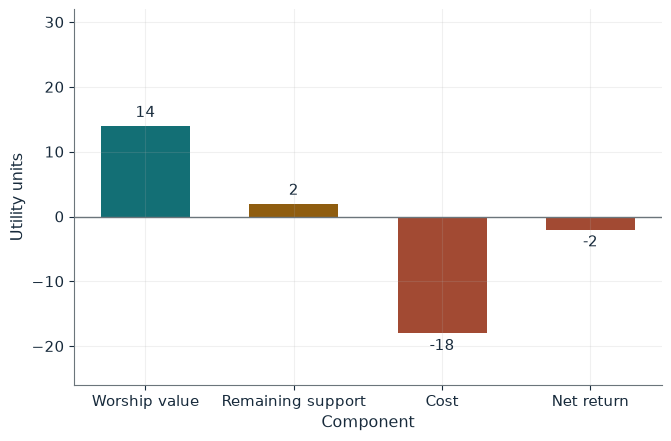

Member             Lina
Remaining support  2
Net return         -2
Decision           Stop

Worked steps:
  1. Remaining support = 9 - 7 = 2
  2. Net return = 14 + 2 - 18 = -2
  3. -2 < 0: the return is negative and the member stops attending

Hypothetical teaching values, not estimates of real communities. For Lina, with worship and identity value 14 and a public benefit that replaces 7 of the 9 support units, the return is 14 + 2 - 18 = -2, so the return is negative and the member stops attending. Belief has not changed; only the support the congregation uniquely supplies has.


In [2]:
show(secular_picture(worship=14, repl=7))

Change one input, `repl`, and hold the others at the book's values:

In [3]:
sweep(secular_picture, 'repl', [0, 2, 7], {'worship': 14}, ['Net return', 'Decision'])

repl | Net return | Decision
0 | 5 | Attend
2 | 3 | Attend
7 | -2 | Stop


Lina's return falls from 5 to -2 when the program replaces 7 units, so she stops attending with no change in belief. Omar (23) keeps a return of 7, and a doubted program (2 units) leaves Lina at 3.

## 2. Religious human-capital accumulation: capital and switching

Hypothetical values: capital depreciates 10 percent a period, the benefit of one unit is 4 + K and its cost 6.

$$K_1^R=0.9(2)+3=4.8, \qquad (4+1.8)-6=-0.2$$

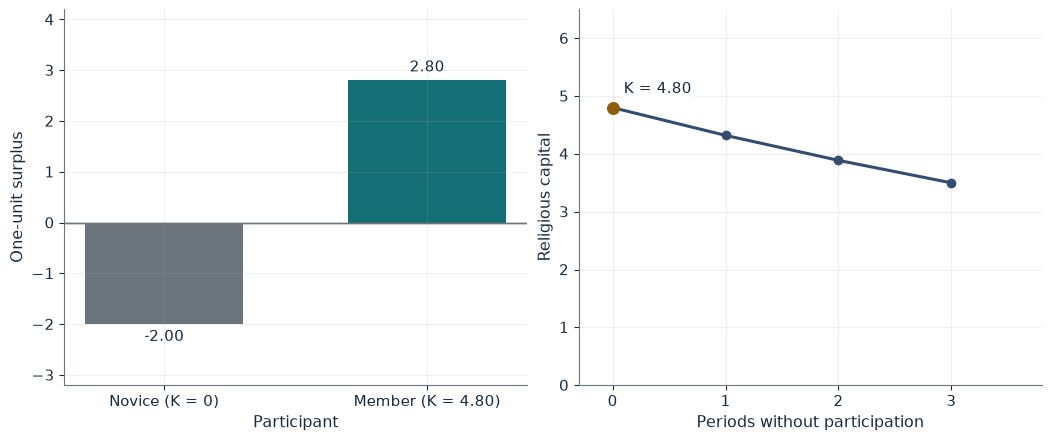

Effective capital  4.80
One-unit surplus   2.80
Novice surplus     -2.00

Worked steps:
  1. Surplus = (4 + 4.80) - 6 = 2.80
  2. Novice surplus = 4 - 6 = -2.00

Hypothetical teaching values, not estimates of real communities. With effective capital 4.80, the one-unit surplus is (4 + 4.80) - 6 = 2.80, so participation pays this period. A novice gets 4 - 6 = -2. Capital of 4.8 in the original tradition, 3.8 after a bridging program and 1.8 when only transferable units count shows why switching is costly.


In [4]:
show(capital_picture(k=4.8, lapse=0))

Change one input, `k`, and hold the others at the book's values:

In [5]:
sweep(capital_picture, 'k', [1.8, 3.8, 4.8], {'lapse': 0}, ['Effective capital', 'One-unit surplus'])

k | Effective capital | One-unit surplus
1.8 | 1.80 | -0.20
3.8 | 3.80 | 1.80
4.8 | 4.80 | 2.80


Capital of 4.8 gives a surplus of 2.80, but only 1.8 transfers to a new tradition (-0.20). A bridging program that keeps 3.8 gives 1.80. Three idle periods cut 4.8 to 3.50.

## 3. Religious household production: time cost and fellowship output

Hypothetical values: full budget 100, goods price 1, time value w per hour.

$$Z=2\sqrt{xt}, \qquad x+4t=100, \qquad Z=2\sqrt{50(12.5)}=50$$

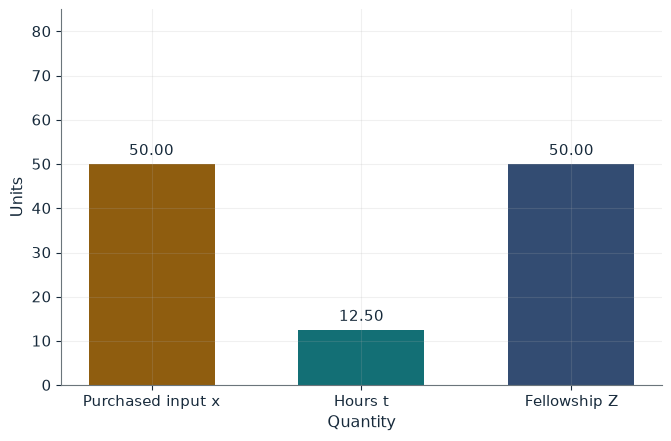

Purchased input x    50.00
Hours t              12.50
Fellowship output Z  50.00
Cash contribution    50.00

Worked steps:
  1. Equal shares: x = 100 / 2 = 50.00; 4t = 50, so t = 50 / 4 = 12.50
  2. Z = 2 sqrt(50.00 x 12.50) = 2 sqrt(625.00) = 50.00
  3. Cash contribution = 50.00 in every state

Hypothetical teaching values, not estimates of real communities. At a time value of 4 per hour, the household spends half the budget on each input: x = 50.00, t = 12.50 hours, and output is Z = 2 sqrt(50.00 x 12.50) = 50.00. Cash contributions stay at 50.00, so an analyst who sees only cash would miss the change in output.


In [6]:
show(fellowship_picture(w=4, remote=1))

Change one input, `w`, and hold the others at the book's values:

In [7]:
sweep(fellowship_picture, 'w', [4, 6, 8], {'remote': 1}, ['Hours t', 'Fellowship output Z', 'Cash contribution'])

w | Hours t | Fellowship output Z | Cash contribution
4 | 12.50 | 50.00 | 50.00
6 | 8.33 | 40.82 | 50.00
8 | 6.25 | 35.36 | 50.00


Doubling the time value halves hours (12.5 to 6.25) and cuts output to 35.36, while cash stays at 50. Remote access that doubles time productivity restores output to 50.

## 4. Religious organizations as social insurance: correlated losses

Hypothetical values: ten households with 40,000 each, a loss of 10,000 and contributions of 1,000 paid before the shock.

$$40{,}000-10{,}000-1{,}000+2{,}000=31{,}000$$

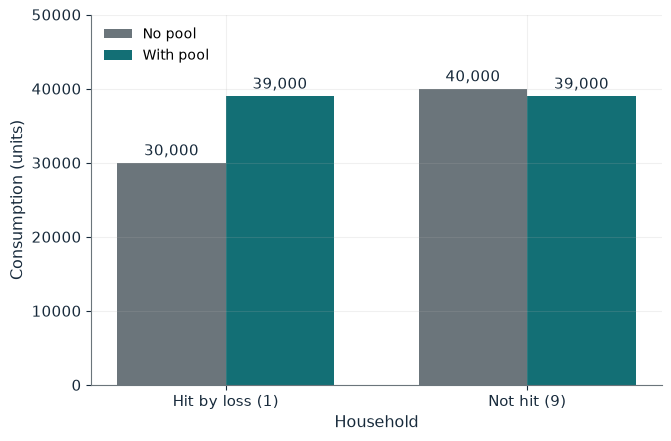

Fund                    10,000
Payout per claimant     10,000
Consumption if hit      39,000
Consumption if not hit  39,000
Fund left over          0

Worked steps:
  1. Fund = 10 x 1,000 = 10,000
  2. Payout = min(10,000, 10,000 / 1) = 10,000
  3. Hit: 40,000 - 10,000 - 1,000 + 10,000 = 39,000
  4. Not hit: 40,000 - 1,000 = 39,000

Hypothetical teaching values, not estimates of real communities. With 1 household hit in the same state and contributions of 1,000, the fund of 10,000 pays each claimant 10,000, covering the full loss. A claimant consumes 40,000 - 10,000 - 1,000 + 10,000 = 39,000 and an unaffected household 39,000. Pooling moves resources across households; it never restores the lost 10,000 per claimant.


In [8]:
show(mutual_aid_picture(n=1, s=1000))

Change one input, `n`, and hold the others at the book's values:

In [9]:
sweep(mutual_aid_picture, 'n', [1, 3, 5], {'s': 1000}, ['Payout per claimant', 'Consumption if hit'])

n | Payout per claimant | Consumption if hit
1 | 10,000 | 39,000
3 | 3,333 | 32,333
5 | 2,000 | 31,000


One claimant is fully covered and everyone consumes 39,000. Five correlated claimants split the 10,000 fund, 2,000 each, and consume 31,000: the local pool gives only partial insurance.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

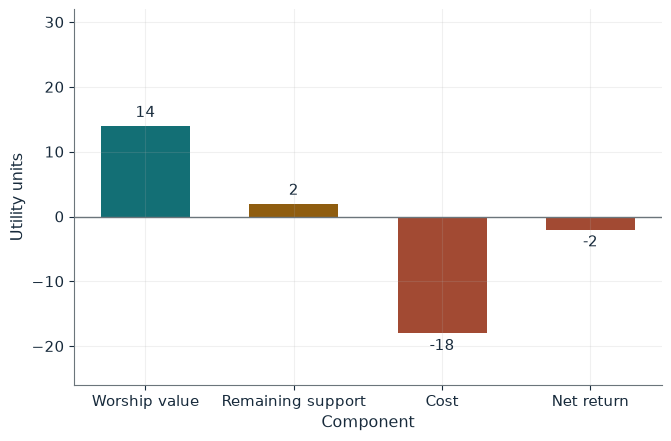

Member             Lina
Remaining support  2
Net return         -2
Decision           Stop

Worked steps:
  1. Remaining support = 9 - 7 = 2
  2. Net return = 14 + 2 - 18 = -2
  3. -2 < 0: the return is negative and the member stops attending

Hypothetical teaching values, not estimates of real communities. For Lina, with worship and identity value 14 and a public benefit that replaces 7 of the 9 support units, the return is 14 + 2 - 18 = -2, so the return is negative and the member stops attending. Belief has not changed; only the support the congregation uniquely supplies has.


In [10]:
show(secular_picture(worship=14, repl=7))

## Practice

**1.** For Omar (worship value 23) with a doubted program replacing 2 units, what is his return?

<details><summary>Answer</summary>

23 + (9 - 2) - 18 = 12, so he attends.

</details>

**2.** With K = 3.8 and a three-period lapse, what is the one-unit surplus?

<details><summary>Answer</summary>

3.8 x 0.9^3 = 2.77, so the surplus is 4 + 2.77 - 6 = 0.77.

</details>

**3.** With three claimants and contributions of 2,000, what does a claimant consume?

<details><summary>Answer</summary>

Fund 20,000 / 3 = 6,667 each; 40,000 - 10,000 - 2,000 + 6,667 = 34,667.

</details>